<img src="https://raw.githubusercontent.com/BiomasBR/prodes-amazonia/main/inst/extdata/sticker/logo-biomas-br.png" align="right" width="80"/>

# Data Cubes - Prodes Pantanal 2026
<hr style="border:2px solid #1e6b3c;">

<center>
    <br>
    <h3>National Institute for Space Research (INPE)</h3>
    <h3>Brazilian Biomes Monitoring Program (BiomasBR)</h3>
    <br>
    <h1>Technical Report</h1>
</center>
<br>

<h4>Coordinators</h4>
<p>
Cláudio A. Almeida and Silvana Amaral
</p>

<h4>Responsible Team</h4>

<p>
Cassiano G. Messias, Luciana de S. Soler,
Guilherme G. Correia, Igor P. Cunha,
Gustavo P. L. Salgado, Miguel A. da Cunha
and Mateus de S. Miranda
</p>





## 1 Introduction

The image composites used for the BiomasBR-Prodes Pantanal 2026 mapping are generated from Sentinel-2 data available through the Brazilian Data Cube (BDC). This Python notebook, based on the BDC tutorial [Introduction to STAC](https://github.com/brazil-data-cube/code-gallery/blob/master/jupyter/Python/stac/stac-introduction.ipynb), demonstrates how to access and visualize the image mosaics and their composition from the biennial data cube across the Pantanal biome grid. Table 1 describes information about the images.


<br>
Table 1 — Description of the characteristics of the Sentinel-2 image cube.

| Item | Description |
|---|---|
| Collection | `S2-16D-2` (BDC catalog) · `SENTINEL-2-16D` (sits) |
| Satellite / sensor | Sentinel-2A and 2B / MSI, Level-2A (surface reflectance) |
| Spatial resolution | 10 m |
| Grid / projection | BDC_SM_V2, Albers Equal Area; tiles of 105.6 × 105.6 km |
| Temporal composition | 16 days, Least Cloud Cover First |
| Period (Prodes 2026 cube) | 2024-08-01 to 2026-07-31 (two Prodes years) |

## 2 Data Acquisition
<hr style="border:1px solid #1e6b3c;">


<p>In order to obtain and visualize the data cube it is required to install the following packages. </p>

In [1]:
# Remove '#' to install packages
!pip install pystac-client rioxarray numpy matplotlib pyproj shapely geopandas folium

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.1 MB/s  0:00:00
  Attempting uninstall: xarray
    Found existing installation: xarray 2025.12.0
    Uninstalling xarray-2025.12.0:
      Successfully uninstalled xarray-2025.12.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27/27 [pystac-client]


In [2]:
import io
import urllib.request
import warnings
from concurrent.futures import ThreadPoolExecutor
import shapely
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle
from matplotlib.transforms import Affine2D
import rasterio
from rasterio.enums import Resampling
from rasterio.windows import from_bounds
import rioxarray
import pystac_client
import folium
import geopandas as gpd
from PIL import Image as PILImage
from pyproj import Transformer
from shapely.geometry import box, mapping
from shapely.ops import transform
from IPython.display import display

### 2.1 Step 1 – BDC grid over the Pantanal

The `BDC_SM_V2` grid divides Brazil into tiles of 10,560 × 10,560 pixels (105.6 km at 10 m). The code `CCCRRR` gives the column (eastwards) and the row (southwards). Twenty-eight tiles intersect the Pantanal. The tiles are drawn without fill, so the satellite image and the biome boundaries remain visible.

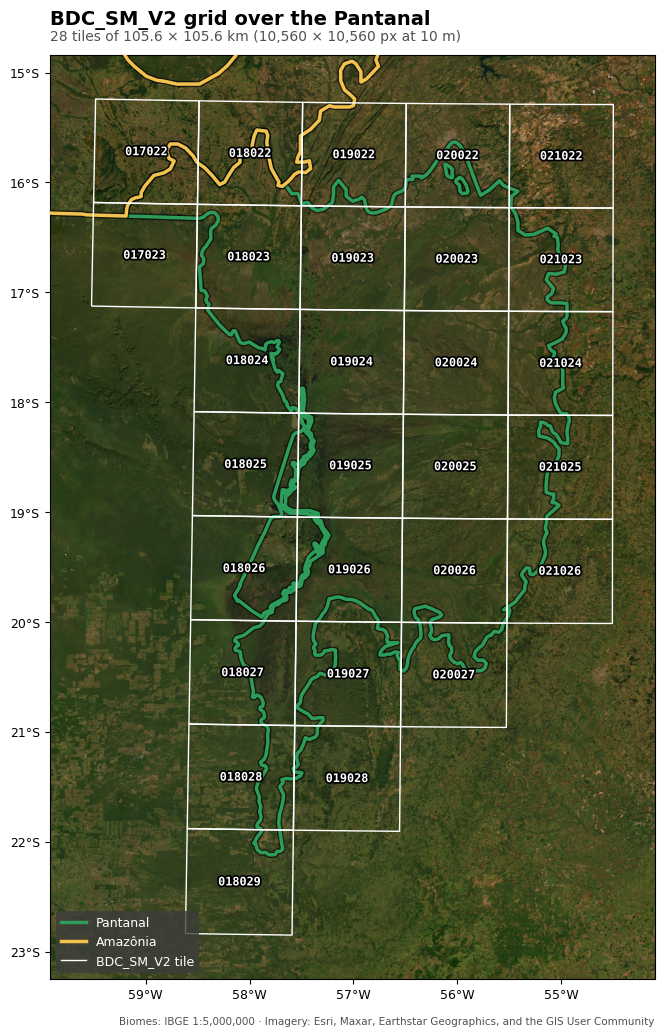

In [3]:
# BDC projection (Albers Equal Area)
proj_bdc = "+proj=aea +lat_0=-12 +lon_0=-54 +lat_1=-2 +lat_2=-22 +x_0=5000000 +y_0=10000000 +ellps=GRS80 +units=m +no_defs"

# Tiles of the BDC_SM_V2 grid that intersect the Pantanal
tiles = ["017022","017023","018022","018023","018024","018025","018026","018027","018028","018029",
         "019022","019023","019024","019025","019026","019027","019028",
         "020022","020023","020024","020025","020026","020027",
         "021022","021023","021024","021025","021026"]

SIZE = 105600                                       # 10,560 px × 10 m
to_wgs = Transformer.from_crs(proj_bdc, "EPSG:4326", always_xy=True).transform

def tile_geom(t):
    """Tile outline in WGS84; the edges are densified so they follow the Albers grid."""
    col, row = int(t[:3]), int(t[3:])
    xmin, ymin = 2624000 + col * SIZE, 11848000 - row * SIZE   # BDC_SM_V2 origin
    g = box(xmin, ymin, xmin + SIZE, ymin + SIZE).segmentize(5000)
    return shapely.transform(g, lambda xy: np.column_stack(to_wgs(xy[:, 0], xy[:, 1])))

# Biome boundaries (IBGE 1:5,000,000)
url = "https://raw.githubusercontent.com/jrenan/papai/main/data/biomes-ibge.geojson"
biomes = gpd.read_file(url).rename(columns={"nome": "name_biome"})
biomes = biomes[biomes["name_biome"].isin(["Pantanal", "Amazônia"])].set_crs(4326, allow_override=True)

grid_gdf = gpd.GeoDataFrame({"tile": tiles}, geometry=[tile_geom(t) for t in tiles], crs=4326)
BIOME_COLOURS = {"Pantanal": "#2d9b5a", "Amazônia": "#f2c14e"}

# Satellite background: Esri World Imagery tiles (Web Mercator), resampled to a lon/lat grid
ESRI_URL = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
ESRI_CREDIT = "Imagery: Esri, Maxar, Earthstar Geographics, and the GIS User Community"

def fetch_xyz(z, x, y):
    req = urllib.request.Request(ESRI_URL.format(z=z, x=x, y=y), headers={"User-Agent": "prodes-notebook"})
    with urllib.request.urlopen(req, timeout=30) as r:
        return np.asarray(PILImage.open(io.BytesIO(r.read())).convert("RGB"))

def satellite_background(lon0, lat0, lon1, lat1, width=1800):
    """RGB image of the box (lon0, lat0, lon1, lat1) on a regular lon/lat grid, `width` px wide,
    ready for imshow(extent=(lon0, lon1, lat0, lat1)). Each output row is mapped to its Mercator row."""
    zoom = int(np.clip(np.ceil(np.log2(width * 360 / (256 * (lon1 - lon0)))), 1, 17))
    world = 256 * 2 ** zoom                                    # world size in pixels at this zoom
    gx = lambda lon: (np.asarray(lon) + 180) / 360 * world
    gy = lambda lat: (1 - np.arcsinh(np.tan(np.radians(lat))) / np.pi) / 2 * world
    tx = range(int(gx(lon0) // 256), int(gx(lon1) // 256) + 1)
    ty = range(int(gy(lat1) // 256), int(gy(lat0) // 256) + 1)
    with ThreadPoolExecutor(16) as ex:                         # parallel downloads
        imgs = list(ex.map(lambda xy: fetch_xyz(zoom, *xy), [(x, y) for y in ty for x in tx]))
    mosaic = np.vstack([np.hstack(imgs[i * len(tx):(i + 1) * len(tx)]) for i in range(len(ty))])
    height = int(width * (lat1 - lat0) / (lon1 - lon0) / np.cos(np.radians((lat0 + lat1) / 2)))
    lons = lon0 + (np.arange(width) + 0.5) * (lon1 - lon0) / width
    lats = lat1 - (np.arange(height) + 0.5) * (lat1 - lat0) / height
    cols = np.clip((gx(lons) - tx[0] * 256).astype(int), 0, mosaic.shape[1] - 1)
    rows = np.clip((gy(lats) - ty[0] * 256).astype(int), 0, mosaic.shape[0] - 1)
    return mosaic[rows][:, cols]

def grid_figure(highlight=None, basemap=True, pad=0.4):
    """Static map of the BDC_SM_V2 tiles over the Pantanal on a satellite image.
    highlight = tile code outlined in yellow; basemap=False draws a plain background."""
    fig, ax = plt.subplots(figsize=(8.5, 12))
    x0, y0, x1, y1 = grid_gdf.total_bounds
    lon0, lat0, lon1, lat1 = x0 - pad, y0 - pad, x1 + pad, y1 + pad

    on_image = False
    if basemap:
        try:
            ax.imshow(satellite_background(lon0, lat0, lon1, lat1), extent=(lon0, lon1, lat0, lat1),
                      interpolation="antialiased", zorder=0)
            on_image = True
        except Exception as e:
            print(f"Satellite image not available ({type(e).__name__}: {e}); plotting without it.")
    ax.set_xlim(lon0, lon1); ax.set_ylim(lat0, lat1)
    ax.set_aspect(1 / np.cos(np.radians((lat0 + lat1) / 2)))   # true shape at this latitude
    edge, ink, halo = ("white", "white", "black") if on_image else ("#3d3d3a", "#0b0b0b", "white")
    if not on_image:
        ax.set_facecolor("#f1efe8")
    line_halo = [pe.withStroke(linewidth=4.5, foreground="black", alpha=0.6)] if on_image else None

    for name, c in BIOME_COLOURS.items():
        biomes[biomes["name_biome"] == name].boundary.plot(ax=ax, color=c, lw=2.5, zorder=3,
                                                           path_effects=line_halo)
    grid_gdf.boundary.plot(ax=ax, color=edge, lw=1, zorder=4)
    if highlight is not None:
        grid_gdf[grid_gdf["tile"] == highlight].boundary.plot(ax=ax, color="#ffff00", lw=3, zorder=5)
    for t, g in zip(grid_gdf["tile"], grid_gdf.geometry):
        ax.text(g.centroid.x, g.centroid.y, t, ha="center", va="center", fontsize=8.5, fontweight="bold",
                family="monospace", color=ink, zorder=6, clip_on=True,
                path_effects=[pe.withStroke(linewidth=2.5, foreground=halo)])

    handles = [Line2D([], [], color=c, lw=2.5, label=n) for n, c in BIOME_COLOURS.items()]
    handles.append(Line2D([], [], color=edge, lw=1, label="BDC_SM_V2 tile"))
    if highlight is not None:
        handles.append(Line2D([], [], color="#ffff00", lw=3, label=f"Tile {highlight}"))
    leg = ax.legend(handles=handles, loc="lower left", frameon=True, fontsize=9)
    leg.get_frame().set_facecolor("#3d3d3a" if on_image else "white")
    leg.get_frame().set_edgecolor("none")
    if on_image:
        for txt in leg.get_texts():
            txt.set_color("white")

    ax.xaxis.set_major_formatter(lambda v, _: f"{abs(v):.0f}°{'W' if v < 0 else 'E'}")
    ax.yaxis.set_major_formatter(lambda v, _: f"{abs(v):.0f}°{'S' if v < 0 else 'N'}")
    ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(labelsize=9)
    ax.set_title("BDC_SM_V2 grid over the Pantanal", loc="left", fontsize=14, fontweight="bold", pad=22)
    ax.text(0, 1.012, f"{len(tiles)} tiles of 105.6 × 105.6 km (10,560 × 10,560 px at 10 m)",
            transform=ax.transAxes, va="bottom", fontsize=10, color="#52514e")
    credits = "Biomes: IBGE 1:5,000,000" + (f" · {ESRI_CREDIT}" if on_image else "")
    ax.text(1, -0.04, credits, transform=ax.transAxes, ha="right", va="top", fontsize=7.5, color="#52514e")
    return fig

fig = grid_figure()                     # e.g. grid_figure(highlight="019025") after choosing the tile
fig.savefig("BDC_grid_Pantanal.png", dpi=200, bbox_inches="tight")
plt.show()

### 2.2 Step 2 – Connecting to the catalog

The BDC publishes its images through a **STAC** service (SpatioTemporal Asset Catalog): the catalog holds collections, each collection holds items (one 16-day composite of one tile) and each item points to one file (asset) per band.

In [4]:
catalog = pystac_client.Client.open("https://data.inpe.br/bdc/stac/v1/")

collection = catalog.get_collection("S2-16D-2")
print(collection.title)
print("Temporal extent:", collection.extent.temporal.intervals)

Sentinel-2/MSI - Level-2A - Data Cube - LCF 16 days
Temporal extent: [[datetime.datetime(2017, 1, 1, 0, 0, tzinfo=tzutc()), datetime.datetime(2026, 10, 15, 0, 0, tzinfo=tzutc())]]


### 2.3 Step 3 – Choosing the tile

Type the code of the tile you want to explore (any of the tiles shown in Step 1). The search returns all composites of that tile in the two-year period of the Prodes 2026 cube.

In [5]:
# >>> Type the tile code here <<<
TILE = "019025"

START = "2024-08-01"
END   = "2026-07-31"

assert TILE in tiles, f"Tile {TILE} does not intersect the Pantanal"

centre = tile_geom(TILE).centroid
search = catalog.search(
    collections=["S2-16D-2"],
    bbox=[centre.x - 0.01, centre.y - 0.01, centre.x + 0.01, centre.y + 0.01],
    datetime=f"{START}T00:00:00Z/{END}T23:59:59Z",
    limit=100,
)

# keep the composites of this tile whose reference date is inside the period
items = sorted([i for i in search.items()
                if TILE in i.properties["bdc:tiles"] and str(i.datetime.date()) >= START],
               key=lambda i: i.datetime)

print(f"Tile {TILE}: {len(items)} composites")            # 46
print("First:", items[0].datetime.date(), "| Last:", items[-1].datetime.date())
print("Bands:", list(items[-1].assets))

/tmp/ipykernel_1801/4245239769.py:10: PystacClientWarning: The requested method 'POST' is not advertised by any root catalog search link. Available methods: GET
  search = catalog.search(


Tile 019025: 46 composites
First: 2024-08-12 | Last: 2026-07-28
Bands: ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09', 'B11', 'B12', 'B8A', 'EVI', 'NBR', 'SCL', 'NDVI', 'CLEAROB', 'TOTALOB', 'thumbnail', 'PROVENANCE']


## 3 Viewing the images of the cube
<hr style="border:1px solid #1e6b3c;">

###3.1  Bands and indices used in the mapping

The cube used in Prodes Pantanal has 14 layers per date, always in this order:

| # | Band | Description | Wavelength (µm) |
|---|---|---|---|
| 1 | B02 | Blue | 0.49 |
| 2 | B03 | Green | 0.56 |
| 3 | B04 | Red | 0.66 |
| 4 | B05 | Red edge 1 | 0.70 |
| 5 | B06 | Red edge 2 | 0.74 |
| 6 | B07 | Red edge 3 | 0.78 |
| 7 | B08 | Near infrared (NIR) | 0.83 |
| 8 | B8A | Narrow NIR | 0.86 |
| 9 | B11 | Shortwave infrared 1 (SWIR1) | 1.61 |
| 10 | B12 | Shortwave infrared 2 (SWIR2) | 2.20 |
| 11 | NDVI | (B08 − B04) / (B08 + B04) | – |
| 12 | NBR | (B08 − B12) / (B08 + B12) | – |
| 13 | EVI | 2.5 (B08 − B04) / (B08 + 6 B04 − 7.5 B02 + 1) | – |
| 14 | SCL (CLOUD) | Scene classification, used only to mask clouds and shadows | – |

Reflectances and indices are stored as integers × 10,000 (scale factor 0.0001).

### Colour compositions

An RGB composition assigns three layers to the red, green and blue channels:

* **True colour – B04 / B03 / B02:** the scene as seen by the eye.
* **False colour – B12 / B8A / B04:** the composition used in the BDC quicklooks. Vegetation appears green, exposed soil and recent clearings pink/magenta, water dark blue/black and burned areas dark red.
* **False colour – B08 / B11 / B04:** NIR in red highlights vegetation vigour; SWIR1 separates soil and dry vegetation.

The cells below read a selected tile, build the compositions and save them as PNG files.

In [6]:
# Choose the date (index of the composite, -1 = last)
item = items[-1]
DATE = str(item.datetime.date())

# 40 m -> 2,640 x 2,640 px.
RES = 40

def read_band(band):
    """Whole tile at RES metres. GDAL reads the COG overviews when they exist, so only part of
    the file is transferred. No-data pixels become NaN."""
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=3, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open(item.assets[band].href) as src:
            shape = (round(src.height * src.res[1] / RES), round(src.width * src.res[0] / RES))
            arr = src.read(1, out_shape=shape, resampling=Resampling.average, masked=True)
    return arr.astype("float32").filled(np.nan) * 1e-4                     # scale factor

def stretch(rgb):
    lo, hi = np.nanpercentile(rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo), 0, 1)

def composite(names):
    """Stretched RGB plus an alpha channel, so no-data pixels are transparent."""
    rgb = stretch(np.dstack([bands[b] for b in names]))
    alpha = np.isfinite(rgb).all(axis=-1)
    return np.dstack([np.nan_to_num(rgb), alpha]).astype("float32")

BAND_LIST = ["B02", "B03", "B04", "B08", "B8A", "B11", "B12", "NDVI"]
with ThreadPoolExecutor(8) as ex:                                         # parallel reads
    bands = dict(zip(BAND_LIST, ex.map(read_band, BAND_LIST)))

compositions = {
    "true_colour_B04-B03-B02":   ["B04", "B03", "B02"],
    "prodes_colour_B08-B11-B04": ["B11", "B08", "B04"],
}
rgb_images = {name: composite(rgb) for name, rgb in compositions.items()}

for name, img in rgb_images.items():
    plt.imsave(f"{TILE}_{DATE}_{name}.png", img)

plt.imsave(f"{TILE}_{DATE}_NDVI.png", bands["NDVI"], cmap="RdYlGn", vmin=-0.2, vmax=1)
h, w = bands["NDVI"].shape
print(f"PNG files saved: whole tile {TILE}, {w} x {h} px at {RES} m.")

PNG files saved: whole tile 019025, 2640 x 2640 px at 40 m.


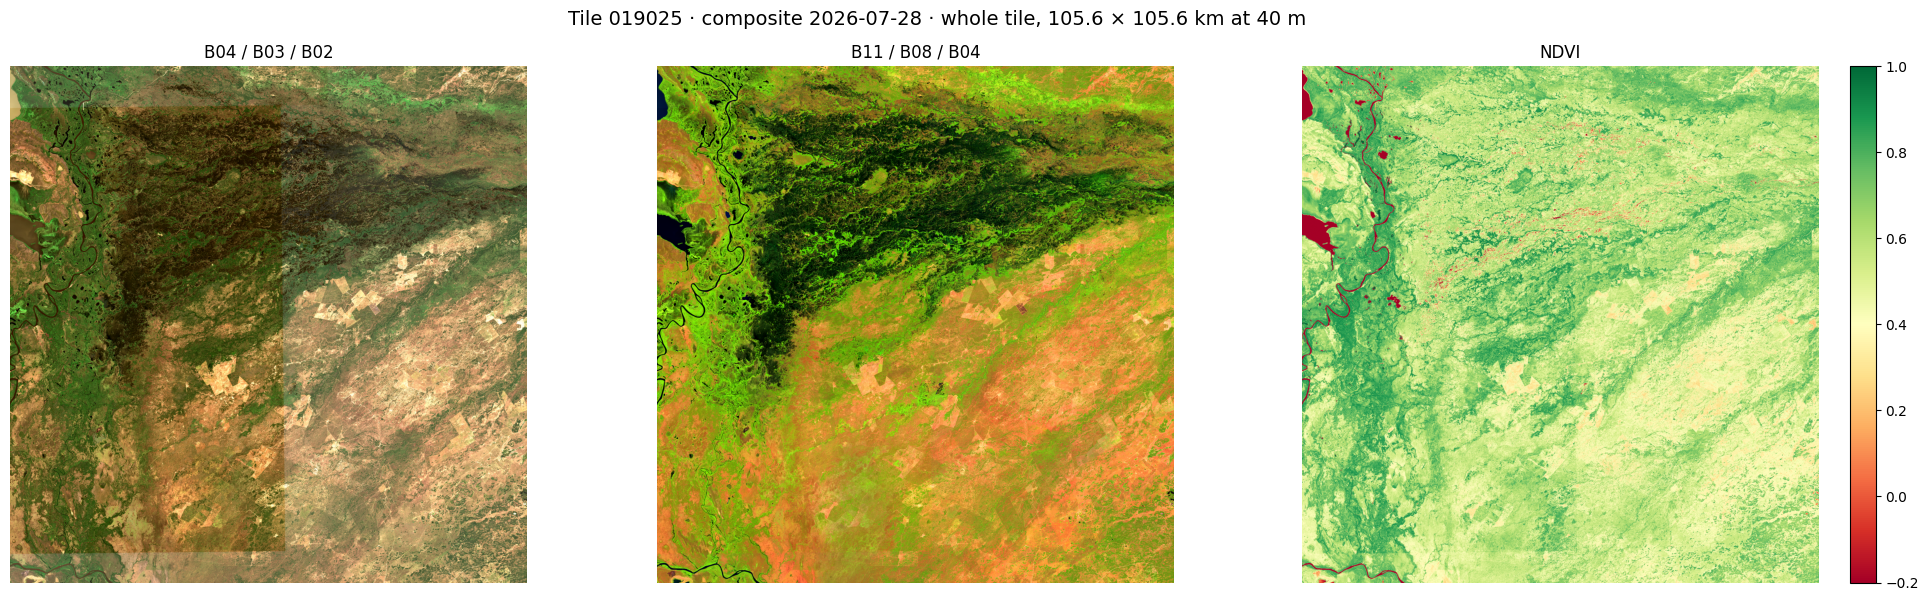

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
for a, (name, rgb) in zip(ax[:2], compositions.items()):
    a.imshow(rgb_images[name])
    a.set_title(" / ".join(rgb))
im = ax[2].imshow(bands["NDVI"], cmap="RdYlGn", vmin=-0.2, vmax=1)
ax[2].set_title("NDVI")
fig.colorbar(im, ax=ax[2], fraction=.046)
for a in ax:
    a.axis("off")
fig.suptitle(f"Tile {TILE} · composite {DATE} · whole tile, 105.6 × 105.6 km at {RES} m", fontsize=14)
plt.tight_layout()
plt.show()

### 3.2 Quicklooks of the area of interest

Each composite of the cube can be inspected over a user-defined area of interest. Set `BBOX` (lon_min, lat_min, lon_max, lat_max, in degrees, WGS84) in the cell below: for each selected date, the function reads the false-colour composition B12 / B8A / B04 (the same used in the BDC quicklooks) directly from the Cloud Optimized GeoTIFFs, at the 10 m resolution of the cube, over the `BBOX` plus a margin. The dashed box marks the `BBOX`; `margin` controls how much of the surroundings is shown (0 = crop exactly to the box). Reading time grows with the size of the area.

The grid puts the two Prodes years in rows and the same 16-day period of each year in columns (August, November, February and July), so seasonal differences and changes between years can be compared side by side. To show other periods, change `positions` (0 = first composite of August … 22 = last composite of July). All panels share the same contrast stretch, so colours are comparable across dates.

If `BBOX = None`, the function shows instead the PNG thumbnails produced by the BDC for the whole tile (105.6 × 105.6 km, low resolution). In this case no box is drawn, and the contrast is the one applied by the BDC, not the shared stretch.

Tile 019025 covers lon -57.5391 to -56.5189, lat -19.0554 to -18.0995


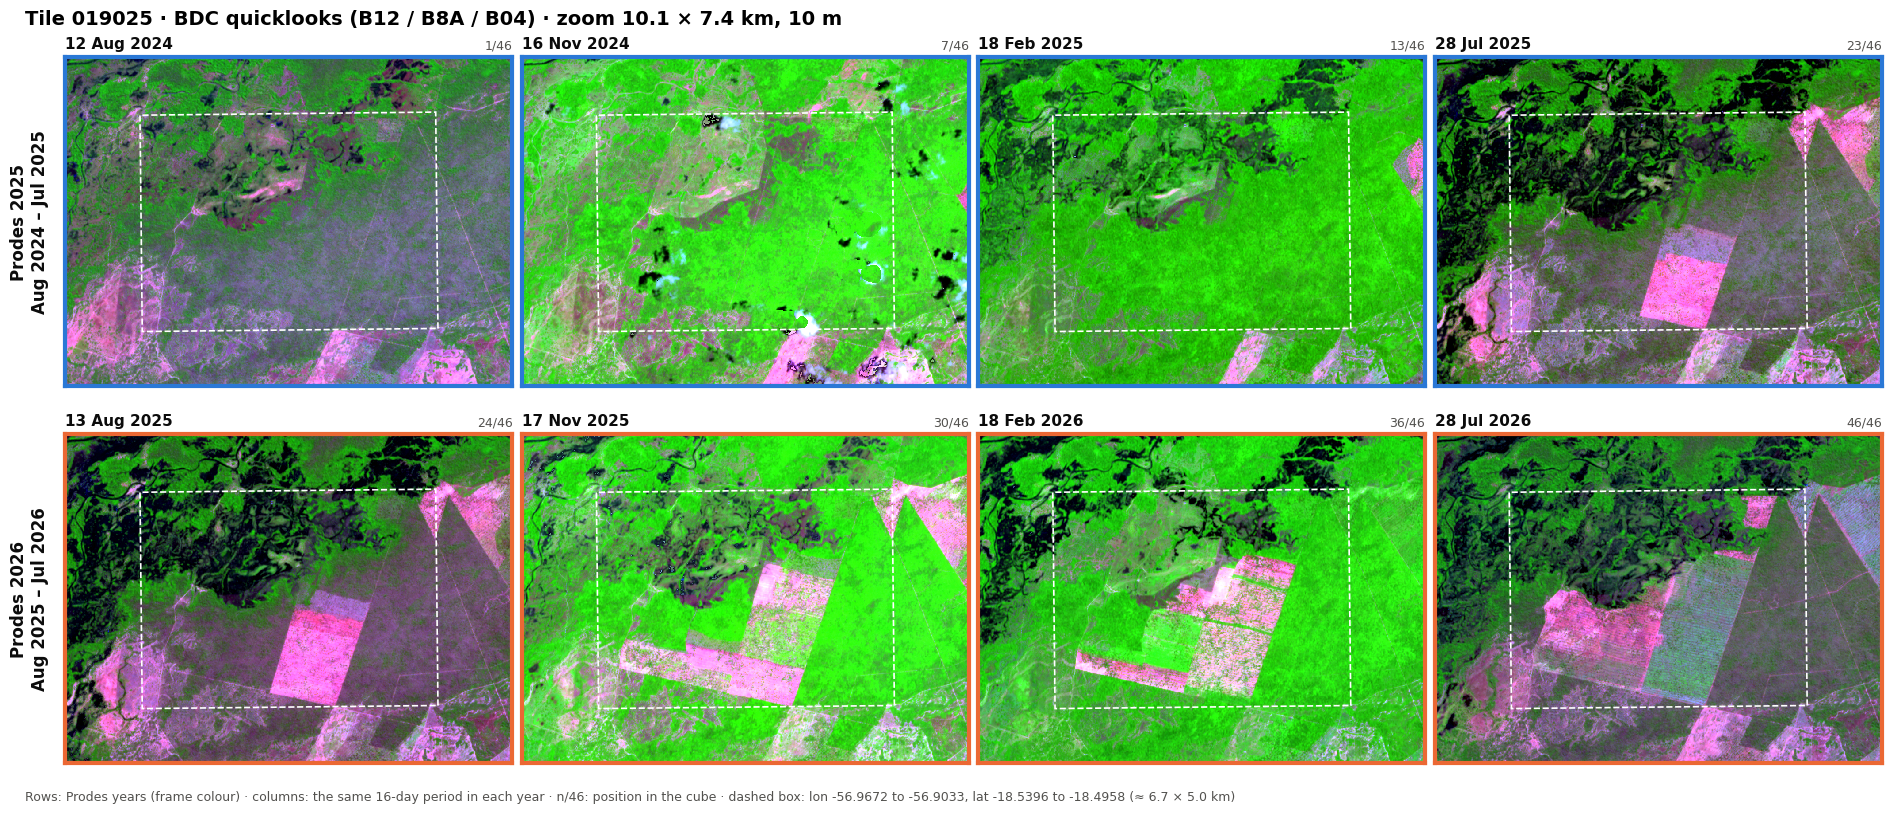

In [8]:
# Prodes year: 1 August of the previous year to 31 July
def prodes_year(d):
    return d.year + 1 if d.month >= 8 else d.year

# One colour per Prodes year (used in every figure from here on)
YEAR_COLOURS = {2025: "#2a78d6", 2026: "#eb6834"}
INK, MUTED = "#0b0b0b", "#52514e"

import shapely
from matplotlib.patches import Polygon as MplPolygon
to_bdc = Transformer.from_crs("EPSG:4326", proj_bdc, always_xy=True).transform

def reproject(geom, fn):
    """Apply a pyproj transform to a shapely geometry (replaces the deprecated shapely.ops.transform)."""
    return shapely.transform(geom, lambda xy: np.column_stack(fn(xy[:, 0], xy[:, 1])))

def tile_bounds(t):
    """Extent of a BDC_SM_V2 tile in the BDC projection: (xmin, ymin, xmax, ymax), in metres."""
    col, row = int(t[:3]), int(t[3:])
    xmin, ymin = 2624000 + col * SIZE, 11848000 - row * SIZE
    return xmin, ymin, xmin + SIZE, ymin + SIZE

def bbox_to_bdc(bbox):
    """(lon_min, lat_min, lon_max, lat_max) in WGS84 degrees -> polygon in the BDC projection.
    The edges are densified, so the box follows the meridians and parallels after projection."""
    lon0, lat0, lon1, lat1 = bbox
    assert lon0 < lon1 and lat0 < lat1, "BBOX must be (lon_min, lat_min, lon_max, lat_max)"
    return reproject(box(lon0, lat0, lon1, lat1).segmentize(0.005), to_bdc)

def fetch_thumbnail(item):
    with urllib.request.urlopen(item.assets["thumbnail"].href, timeout=60) as r:
        return np.asarray(PILImage.open(io.BytesIO(r.read())).convert("RGB"))

def quicklook_grid(items, positions=(0, 6, 12, 22), panel=4.5, bbox=None, margin=0.25,
                   bands=("B12", "B8A", "B04"), res=10):
    """
    bbox   = (lon_min, lat_min, lon_max, lat_max) em degres. If specified, each panel acts as a ZOOM
    into the BBOX area (read directly from the COGs, at a resolution of `res` meters), with the BBOX
    outlined by a dashed line. If None, the entire tile is displayed (STAC catalog thumbnail).
    margin = folga ao redor do BBOX, como fração do seu tamanho (0 = recorta rente ao BBOX).
    bands  = composição RGB do zoom (padrão: falsa-cor B12/B8A/B04, igual ao quicklook do BDC).
    """
    order = {it.id: k for k, it in enumerate(items)}
    years = sorted({prodes_year(it.datetime) for it in items})
    by_year = {y: [it for it in items if prodes_year(it.datetime) == y] for y in years}
    grid = [[by_year[y][p] if p < len(by_year[y]) else None for p in positions] for y in years]

    tx0, ty0, tx1, ty1 = tile_bounds(TILE)
    roi, win = None, (tx0, ty0, tx1, ty1)
    if bbox is not None:
        roi = bbox_to_bdc(bbox)
        if not roi.intersects(box(tx0, ty0, tx1, ty1)):
            a, b, c, d = reproject(box(tx0, ty0, tx1, ty1).segmentize(5000), to_wgs).bounds
            warnings.warn(f"BBOX {bbox} is outside tile {TILE} (lon {a:.4f} to {c:.4f}, "
                          f"lat {b:.4f} to {d:.4f}); no box drawn.")
            roi = None
        else:
            bx0, by0, bx1, by1 = roi.bounds
            mx, my = (bx1 - bx0) * margin, (by1 - by0) * margin
            win = (max(bx0 - mx, tx0), max(by0 - my, ty0),      # janela do zoom, limitada ao tile
                   min(bx1 + mx, tx1), min(by1 + my, ty1))
    zoom = roi is not None
    wx0, wy0, wx1, wy1 = win

    def read_rgb(it):
        """Lê as 3 bandas na janela `win` e devolve array (h, w, 3) com NaN onde não há dado."""
        ny, nx = max(1, round((wy1 - wy0) / res)), max(1, round((wx1 - wx0) / res))
        chans = []
        for b in bands:
            with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
                              GDAL_HTTP_MAX_RETRY=3, GDAL_HTTP_RETRY_DELAY=2):
                with rasterio.open(it.assets[b].href) as src:
                    arr = src.read(1, window=from_bounds(*win, transform=src.transform),
                                   out_shape=(ny, nx), resampling=Resampling.nearest, masked=True)
            chans.append(arr.astype("float32").filled(np.nan))
        return np.dstack(chans)

    todo = [it for row in grid for it in row if it is not None]
    with ThreadPoolExecutor(8) as ex:
        if zoom:
            raw = dict(zip([it.id for it in todo], ex.map(read_rgb, todo)))
            # esticamento COMUM a todos os painéis (2–98 %), para as datas serem comparáveis
            allv = np.concatenate([a.reshape(-1, 3) for a in raw.values()])
            lo, hi = np.nanpercentile(allv, [2, 98], axis=0)
            imgs = {k: np.nan_to_num(np.clip((a - lo) / (hi - lo), 0, 1)) for k, a in raw.items()}
        else:
            imgs = dict(zip([it.id for it in todo], ex.map(fetch_thumbnail, todo)))

    aspect = (wy1 - wy0) / (wx1 - wx0)
    fig, axes = plt.subplots(len(years), len(positions), squeeze=False, layout="constrained",
                             figsize=(panel * len(positions) + 0.8,
                                      (panel * aspect + 0.7) * len(years)))
    for r, y in enumerate(years):
        for ax, it in zip(axes[r], grid[r]):
            ax.set_xticks([]); ax.set_yticks([])
            if it is None:
                ax.set_visible(False); continue
            ax.imshow(imgs[it.id], extent=(wx0, wx1, wy0, wy1),
                      interpolation="nearest" if zoom else "antialiased")
            ax.set_xlim(wx0, wx1); ax.set_ylim(wy0, wy1)             # <- enquadra na janela do BBOX
            for s in ax.spines.values():                            # frame = Prodes year
                s.set_edgecolor(YEAR_COLOURS.get(y, MUTED)); s.set_linewidth(3)
            ax.set_title(f"{it.datetime:%d %b %Y}", loc="left", fontsize=11, fontweight="bold", color=INK)
            ax.set_title(f"{order[it.id] + 1}/{len(items)}", loc="right", fontsize=9, color=MUTED)
            if roi is not None:
                ax.add_patch(MplPolygon(np.asarray(roi.exterior.coords), closed=True,
                                        fill=False, ec="white", lw=1.2, ls="--"))
        axes[r, 0].set_ylabel(f"Prodes {y}\nAug {y - 1} – Jul {y}", fontsize=12,
                              fontweight="bold", color=INK, labelpad=12)

    box_note = ""
    if roi is not None:
        bx0, by0, bx1, by1 = roi.bounds
        box_note = (f" · dashed box: lon {bbox[0]:.4f} to {bbox[2]:.4f}, lat {bbox[1]:.4f} to {bbox[3]:.4f}"
                    f" (≈ {(bx1 - bx0) / 1000:.1f} × {(by1 - by0) / 1000:.1f} km)")
    extent_txt = (f"zoom {(wx1 - wx0) / 1000:.1f} × {(wy1 - wy0) / 1000:.1f} km, {res} m"
                  if zoom else "105.6 × 105.6 km")
    rgb_txt = " / ".join(bands) if zoom else "B12 / B8A / B04"
    fig.suptitle(f"Tile {TILE} · BDC quicklooks ({rgb_txt}) · {extent_txt}",
                 x=0.01, ha="left", fontsize=14, fontweight="bold")
    fig.supxlabel("Rows: Prodes years (frame colour) · columns: the same 16-day period in each year · "
                  f"n/{len(items)}: position in the cube{box_note}",
                  x=0.01, ha="left", fontsize=9, color=MUTED)
    return fig

lon_a, lat_a, lon_b, lat_b = reproject(box(*tile_bounds(TILE)).segmentize(5000), to_wgs).bounds
print(f"Tile {TILE} covers lon {lon_a:.4f} to {lon_b:.4f}, lat {lat_a:.4f} to {lat_b:.4f}")

# >>> Bounding box in WGS84 degrees: (lon_min, lat_min, lon_max, lat_max) >>>ALTERAR AQUI <<<
BBOX = (-56.96720, -18.53962, -56.90329, -18.49581)

# >>> Choose the composite positions inside each Prodes year (0–22) <<<
fig = quicklook_grid(items, positions=(0, 6, 12, 22), bbox=BBOX)     # Aug · Nov · Feb · Jul
fig.savefig(f"{TILE}_quicklooks.png", dpi=150, bbox_inches="tight")
plt.show()

## 4 The two-year data cube
<hr style="border:1px solid #1e6b3c;">

### 4.1 Size of the cube

Prodes maps change over the Prodes year (1 August – 31 July). The classification uses two complete Prodes years: for Prodes Pantanal 2026, **1 Aug 2024 – 31 Jul 2026**. BDC composites restart every 1 January and advance 16 days, so each year has 23 composites. All composites in the period are used (no date or cloud filter); clouds are handled by the SCL/CLOUD band.

The cell below lists the composites of each Prodes year and estimates the size of the cube from the data types declared in the catalog.

In [9]:
LAYERS = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12", "NDVI", "NBR", "EVI", "SCL"]
npix = (SIZE // 10) ** 2                                   # 10,560 × 10,560 px at 10 m

def dtype_of(band):
    """Data type declared in the STAC item (raster extension); int16 / uint8 (SCL) if absent."""
    rb = items[-1].assets[band].extra_fields.get("raster:bands") or [{}]
    return np.dtype(rb[0].get("data_type", "uint8" if band == "SCL" else "int16"))

bytes_per_date = npix * sum(dtype_of(b).itemsize for b in LAYERS)

for y in sorted({prodes_year(it.datetime) for it in items}):
    d = [it.datetime.date() for it in items if prodes_year(it.datetime) == y]
    print(f"Prodes {y}: {len(d)} composites  {d[0]} → {d[-1]}")

n, nt = len(items), len(tiles)
summary = pd.DataFrame(
    {"Per tile": [n, n * len(LAYERS), n * bytes_per_date / 1e9],
     f"All {nt} Pantanal tiles": [n * nt, n * len(LAYERS) * nt, n * bytes_per_date * nt / 1e9]},
    index=["Composites (dates)", f"Image files ({len(LAYERS)} layers × dates)", "Uncompressed volume (GB)"])
display(summary.style.format("{:,.0f}"))

Prodes 2025: 23 composites  2024-08-12 → 2025-07-28
Prodes 2026: 23 composites  2025-08-13 → 2026-07-28


,Per tile,All 28 Pantanal tiles
Composites (dates),46,"1,288"
Image files (14 layers × dates),644,"18,032"
Uncompressed volume (GB),138,"3,878"


The files are stored as compressed Cloud Optimized GeoTIFFs (COG), so the space on disk is smaller than the uncompressed volume; the uncompressed figure is what matters when the cube is loaded into memory for processing.

### 4.2 Visualising the cube

A data cube is a three-dimensional array: two spatial dimensions (x, y) and time. The next cell reads the **NDVI** and **SCL** layers of the 20 × 20 km window of 3.1 for all 46 composites, at 80 m (250 × 250 px), masks clouds, shadows and no-data with SCL and stores the result in an `xarray.DataArray` named `cube` (dimensions *time × y × x*). The reads run in parallel and use the overviews of the COG files when available, so only a small part of each file is transferred.

The figure then shows the cube in three ways:

* **Cube view** – the front face is the last composite; the top and right faces are the north row and the east column of the window through time, so each stripe is one date. Seasonal greening, flooding and cloud gaps appear as bands; a lasting change (a clearing, for example) appears as a sharp break from one date onwards. The dashed line marks the change of Prodes year.
* **Temporal profile** – median NDVI of the valid pixels of each date (shaded band: 25–75 % of the pixels) and the share of valid pixels, which shows when clouds remove data.
* **All dates** – the 46 NDVI images, one row per Prodes year, aligned by the position of the composite in the year.

Change `CUBE_KM` and `CUBE_PX` to enlarge the window or increase the resolution (reading time grows with the number of pixels).

In [10]:
# >>> Settings of the cube view <<<
CUBE_KM, CUBE_PX = 20, 250          # 20 × 20 km window, read at 250 × 250 px (80 m)
INVALID_SCL = [0, 1, 2, 3, 8, 9, 10, 11]   # no data, saturated, dark area, cloud shadow, clouds, cirrus, snow

cx, cy = Transformer.from_crs("EPSG:4326", proj_bdc, always_xy=True).transform(centre.x, centre.y)
bounds = (cx - CUBE_KM * 500, cy - CUBE_KM * 500, cx + CUBE_KM * 500, cy + CUBE_KM * 500)

def read_window(href, resampling):
    """Read the window at reduced resolution (GDAL uses the COG overviews when they exist)."""
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=3, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open(href) as src:
            arr = src.read(1, window=from_bounds(*bounds, transform=src.transform),
                           out_shape=(CUBE_PX, CUBE_PX), resampling=resampling, masked=True)
    return arr.astype("float32").filled(np.nan)

def read_ndvi(item):
    ndvi = read_window(item.assets["NDVI"].href, Resampling.average) * 1e-4      # scale factor
    scl = read_window(item.assets["SCL"].href, Resampling.nearest)
    ndvi[np.isnan(scl) | np.isin(scl, INVALID_SCL) | (np.abs(ndvi) > 1)] = np.nan
    return ndvi

with ThreadPoolExecutor(8) as ex:                    # 2 reads per date, in parallel
    stack = np.stack(list(ex.map(read_ndvi, items)))

res = CUBE_KM * 1000 / CUBE_PX
cube = xr.DataArray(
    stack, name="NDVI", dims=("time", "y", "x"),
    coords={"time": pd.to_datetime([str(it.datetime.date()) for it in items]),
            "prodes_year": ("time", [prodes_year(it.datetime) for it in items]),
            "y": bounds[3] - res * (np.arange(CUBE_PX) + 0.5),
            "x": bounds[0] + res * (np.arange(CUBE_PX) + 0.5)},
    attrs={"tile": TILE, "collection": "S2-16D-2", "resolution_m": res,
           "masked_SCL_classes": str(INVALID_SCL), "crs": proj_bdc})
cube

<xarray.DataArray 'NDVI' (time: 46, y: 250, x: 250)> Size: 12MB
array([[[0.53319997, 0.46339998, 0.6098    , ..., 0.5196    ,
         0.5938    , 0.70159996],
        [0.4113    , 0.461     , 0.4777    , ..., 0.5703    ,
         0.5128    , 0.72639996],
        [0.4269    , 0.44939998, 0.4251    , ..., 0.69699997,
         0.5855    , 0.7427    ],
        ...,
        [0.303     , 0.3175    , 0.30269998, ..., 0.4594    ,
         0.4294    , 0.5912    ],
        [0.2787    , 0.3089    , 0.2715    , ..., 0.5341    ,
         0.5013    , 0.475     ],
        [0.2624    , 0.29189998, 0.2732    , ..., 0.6027    ,
         0.5318    , 0.5255    ]],

       [[0.5829    , 0.4412    , 0.5852    , ..., 0.5196    ,
         0.63909996, 0.7342    ],
        [0.43559998, 0.45319998, 0.4969    , ..., 0.569     ,
         0.5151    , 0.7837    ],
        [0.4179    , 0.4456    ,        nan, ..., 0.70589995,
         0.5864    , 0.77919996],
...
        [0.3988    , 0.5252    , 0.53279996, ..., 0.71199995,
         0.6735    , 0.8089    ],
        [0.3875    , 0.5349    , 0.48189998, ..., 0.79179996,
         0.7721    , 0.6949    ],
        [0.3872    , 0.49769998, 0.4447    , ..., 0.8418    ,
         0.7665    , 0.7229    ]],

       [[0.6301    , 0.5315    , 0.643     , ..., 0.6556    ,
         0.75869995, 0.8032    ],
        [0.5222    , 0.5627    , 0.4985    , ..., 0.69119996,
         0.7371    , 0.80649996],
        [0.51699996, 0.56979996, 0.5076    , ..., 0.81      ,
         0.782     , 0.8312    ],
        ...,
        [0.34919998, 0.4816    , 0.4781    , ..., 0.5728    ,
         0.55579996, 0.6717    ],
        [0.36229998, 0.5038    , 0.43109998, ..., 0.6428    ,
         0.63519996, 0.57409996],
        [0.3671    , 0.4601    , 0.39699998, ..., 0.70699996,
         0.64489996, 0.6095    ]]], dtype=float32)
Coordinates:
  * time         (time) datetime64[ns] 368B 2024-08-12 2024-08-28 ... 2026-07-28
    prodes_year  (time) int64 368B 2025 2025 2025 2025 ... 2026 2026 2026 2026
  * y            (y) float64 2kB 9.271e+06 9.271e+06 ... 9.251e+06 9.251e+06
  * x            (x) float64 2kB 4.673e+06 4.673e+06 ... 4.693e+06 4.693e+06
Attributes:
    tile:                019025
    collection:          S2-16D-2
    resolution_m:        80.0
    masked_SCL_classes:  [0, 1, 2, 3, 8, 9, 10, 11]
    crs:                 +proj=aea +lat_0=-12 +lon_0=-54 +lat_1=-2 +lat_2=-22...

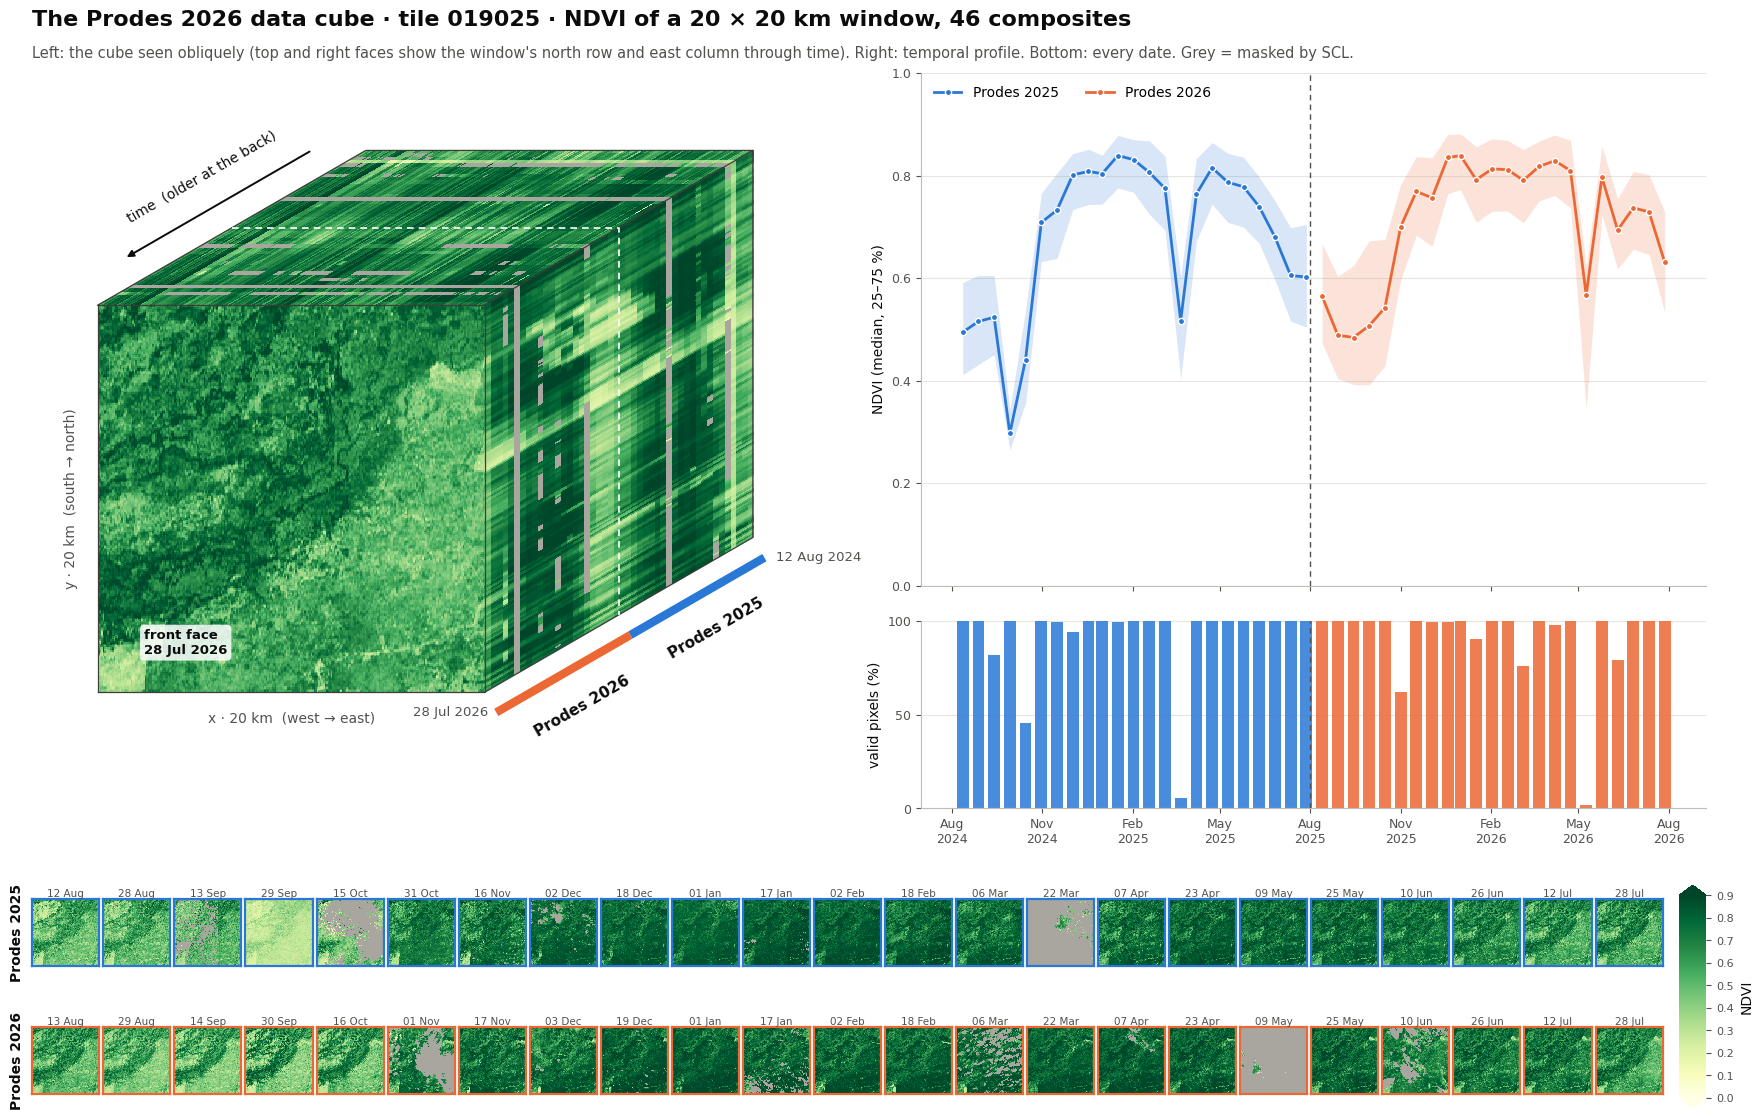

In [11]:
NDVI_CMAP = plt.get_cmap("YlGn").copy()
NDVI_CMAP.set_bad("#a9a6a0")                      # grey = masked (clouds, shadows, no data)
NDVI_NORM = plt.Normalize(0, 0.9)
EDGE = "#3d3d3a"

def draw_cube(ax, cube, depth=0.8, angle=30):
    """Oblique view of a (time, y, x) cube. Front face: last date. Depth: time running back.
    Top face: northern row of the window through time. Right face: eastern column through time."""
    data, years = cube.values, cube.prodes_year.values
    T, H, W = data.shape
    a = np.radians(angle)
    dx, dy = depth * W * np.cos(a) / T, depth * W * np.sin(a) / T      # one time step on screen
    Lx, Ly = dx * T, dy * T
    rev = data[::-1]                                                   # k = 0 → most recent date
    kw = dict(cmap=NDVI_CMAP, norm=NDVI_NORM, interpolation="nearest")

    front = ax.imshow(data[-1], extent=(0, W, 0, H), **kw)
    top = ax.imshow(rev[:, 0, :], extent=(0, W, 0, T), origin="lower", **kw)
    top.set_transform(Affine2D(np.array([[1, dx, 0], [0, dy, H], [0, 0, 1]])) + ax.transData)
    side = ax.imshow(rev[:, :, -1].T, extent=(0, T, 0, H), **kw)
    side.set_transform(Affine2D(np.array([[dx, 0, W], [dy, 1, 0], [0, 0, 1]])) + ax.transData)

    for xs, ys in [((0, W, W, 0, 0), (0, 0, H, H, 0)),
                   ((0, Lx, W + Lx, W), (H, H + Ly, H + Ly, H)),
                   ((W, W + Lx, W + Lx), (0, Ly, H + Ly))]:
        ax.plot(xs, ys, color=EDGE, lw=0.9, solid_joinstyle="miter")

    # Prodes years along the time axis (k counted from the front), offset below the edge
    rev_years, off = years[::-1], 0.06 * H
    ox, oy = off * np.sin(a), -off * np.cos(a)
    for y in np.unique(years):
        ks = np.where(rev_years == y)[0]
        k0, k1 = ks.min(), ks.max() + 1
        ax.plot([W + k0 * dx + ox, W + k1 * dx + ox], [k0 * dy + oy, k1 * dy + oy],
                color=YEAR_COLOURS.get(y, MUTED), lw=6, solid_capstyle="butt")
        km = (k0 + k1) / 2
        ax.text(W + km * dx + 2.6 * ox, km * dy + 2.6 * oy, f"Prodes {y}", rotation=angle,
                rotation_mode="anchor", ha="center", va="center", fontsize=11, fontweight="bold",
                color=INK, transform_rotates_text=True)
        if k0 > 0:                                                     # year boundary on the cube
            ax.plot([k0 * dx, W + k0 * dx, W + k0 * dx], [H + k0 * dy, H + k0 * dy, k0 * dy],
                    color="white", lw=1.2, ls=(0, (4, 3)))
    t0, t1 = (pd.Timestamp(v) for v in cube.time.values[[0, -1]])
    ax.text(W + Lx + ox + 0.03 * W, Ly + oy, f"{t0:%d %b %Y}", ha="left", va="center", fontsize=9.5, color=MUTED)
    ax.text(W + ox - 0.02 * W, oy, f"{t1:%d %b %Y}", ha="right", va="center", fontsize=9.5, color=MUTED)
    nx, ny = -0.07 * H * np.sin(a), 0.07 * H * np.cos(a)              # arrow above the top-left edge
    ax.annotate("", xy=(0.15 * Lx + nx, H + 0.15 * Ly + ny), xytext=(0.85 * Lx + nx, H + 0.85 * Ly + ny),
                arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.4))
    ax.text(0.5 * Lx + 2.2 * nx, H + 0.5 * Ly + 2.2 * ny, "time  (older at the back)", rotation=angle,
            rotation_mode="anchor", ha="center", va="center", fontsize=10, color=INK, transform_rotates_text=True)

    ax.text(W / 2, -0.05 * H, f"x · {CUBE_KM} km  (west → east)", ha="center", va="top", fontsize=10, color=MUTED)
    ax.text(-0.05 * W, H / 2, f"y · {CUBE_KM} km  (south → north)", ha="right", va="center",
            rotation=90, fontsize=10, color=MUTED)
    ax.annotate(f"front face\n{pd.Timestamp(cube.time.values[-1]):%d %b %Y}", xy=(0.12 * W, 0.1 * H),
                fontsize=9.5, color=INK, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="none", alpha=0.85))
    ax.set_xlim(-0.12 * W, W + Lx + 0.22 * W)
    ax.set_ylim(-0.3 * H, H + Ly + 0.2 * H)
    ax.set_aspect("equal"); ax.axis("off")
    return front

def plot_profile(ax_n, ax_v, cube):
    """Median NDVI of the clear pixels (band: 25–75 %) and share of valid pixels per date."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)               # all-masked dates
        med = cube.median(("y", "x"))
        q = cube.quantile([0.25, 0.75], dim=("y", "x"))
    valid = 100 * cube.notnull().mean(("y", "x"))
    t, years = cube.time.values, cube.prodes_year.values
    for y in np.unique(years):
        s, c = years == y, YEAR_COLOURS.get(y, MUTED)
        ax_n.fill_between(t[s], q.sel(quantile=0.25)[s], q.sel(quantile=0.75)[s], color=c, alpha=0.18, lw=0)
        ax_n.plot(t[s], med[s], color=c, lw=2, marker="o", ms=4.5, mec="white", mew=1, label=f"Prodes {y}")
        ax_v.bar(t[s], valid[s], width=np.timedelta64(12, "D"), color=c, alpha=0.85)
    for y in np.unique(years)[1:]:
        for ax in (ax_n, ax_v):
            ax.axvline(np.datetime64(f"{y - 1}-08-01"), color=MUTED, lw=1, ls=(0, (4, 3)))
    ax_n.set_ylabel("NDVI (median, 25–75 %)", color=INK)
    ax_n.set_ylim(min(0, float(q.min()) - 0.05), 1)
    ax_n.legend(loc="upper left", frameon=False, ncols=2)
    ax_v.set_ylabel("valid pixels (%)", color=INK)
    ax_v.set_ylim(0, 100); ax_v.set_yticks([0, 50, 100])
    ax_v.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[2, 5, 8, 11]))
    ax_v.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    for ax in (ax_n, ax_v):
        ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["left", "bottom"]].set_color("#bdbcb6")
        ax.tick_params(colors=MUTED, labelsize=9)
    ax_n.tick_params(labelbottom=False)

def plot_strip(fig, spec, cube):
    """All dates as small multiples: one row per Prodes year, aligned by position in the year."""
    years = np.unique(cube.prodes_year.values)
    ncol = max((cube.prodes_year.values == y).sum() for y in years)
    sub = spec.subgridspec(len(years), ncol, wspace=0.06, hspace=0.35)
    for r, y in enumerate(years):
        sl = cube.sel(time=cube.prodes_year == y)
        for k in range(ncol):
            ax = fig.add_subplot(sub[r, k]); ax.set_xticks([]); ax.set_yticks([])
            if k >= sl.sizes["time"]:
                ax.set_visible(False); continue
            ax.imshow(sl.values[k], cmap=NDVI_CMAP, norm=NDVI_NORM, interpolation="nearest")
            ax.set_title(f"{pd.Timestamp(sl.time.values[k]):%d %b}", fontsize=7.5, color=MUTED, pad=2)
            for s in ax.spines.values():
                s.set_edgecolor(YEAR_COLOURS.get(y, MUTED)); s.set_linewidth(1.6)
            if k == 0:
                ax.set_ylabel(f"Prodes {y}", fontsize=10, fontweight="bold", color=INK, labelpad=6)

fig = plt.figure(figsize=(18, 11.5))
gs = fig.add_gridspec(2, 2, height_ratios=[3.3, 1], width_ratios=[1.05, 1], hspace=0.16, wspace=0.08,
                      left=0.04, right=0.97, top=0.93, bottom=0.03)
im = draw_cube(fig.add_subplot(gs[0, 0]), cube)

right = gs[0, 1].subgridspec(2, 1, height_ratios=[3, 1.1], hspace=0.1)
ax_n = fig.add_subplot(right[0]); ax_v = fig.add_subplot(right[1], sharex=ax_n)
plot_profile(ax_n, ax_v, cube)

bottom = gs[1, :].subgridspec(1, 2, width_ratios=[60, 1], wspace=0.02)
plot_strip(fig, bottom[0], cube)
cb = fig.colorbar(im, cax=fig.add_subplot(bottom[1]), extend="both")
cb.set_label("NDVI", color=INK); cb.ax.tick_params(labelsize=8, colors=MUTED); cb.outline.set_visible(False)

fig.suptitle(f"The Prodes {cube.prodes_year.values.max()} data cube · tile {TILE} · "
             f"NDVI of a {CUBE_KM} × {CUBE_KM} km window, {cube.sizes['time']} composites",
             x=0.04, y=0.985, ha="left", fontsize=16, fontweight="bold", color=INK)
fig.text(0.04, 0.943, "Left: the cube seen obliquely (top and right faces show the window's north row and east "
         "column through time). Right: temporal profile. Bottom: every date. Grey = masked by SCL.",
         fontsize=10.5, color=MUTED)
fig.savefig(f"{TILE}_datacube_NDVI.png", dpi=200, bbox_inches="tight")
plt.show()

## 5 Final remarks
<hr style="border:1px solid #1e6b3c;">

This notebook documents how the image cube of BiomasBR-Prodes Pantanal 2026 is accessed and inspected. The 28 tiles of the `BDC_SM_V2` grid that cover the biome, the connection to the BDC STAC catalog, the selection of the 46 composites of a tile, the 14 layers used in the mapping, and the visual inspection of the data, from a 20 × 20 km window at 10 m to the whole two-year cube. The main points to take from the material are summarised below.

**What the material shows**

* **Temporal structure.** The cube has 23 composites per Prodes year. Because BDC composites restart every 1 January, the two years are aligned almost day by day (12 Aug 2024 ↔ 13 Aug 2025, 18 Feb 2025 ↔ 18 Feb 2026), thus the composite *k* of one year can be compared directly with composite *k* of the other. This is the alignment used in the grids of 3.2 and 4.2, and it is also a simple way to form two-date (bitemporal) pairs from the same season. The last composite of each calendar year (starting on 18 or 19 December) is shorter, because it ends on 31 December.
* **Seasonality.** In the Pantanal the rainy season (roughly October to March) and the flood pulse that follows it change the surface response strongly within the same year, i.e., flooded fields, wet and dry grasslands and burned areas alternate. The cube view and the temporal profile make this variability visible. Using the complete time series, rather than one or two dates, helps to separate this natural cycle from the actual conversion of native vegetation.
* **Clouds.** Least Cloud Cover First compositing reduces clouds but does not remove them, especially in the rainy season. The share of valid pixels per date (4.2) quantifies the gaps, which must be filled before classification, for example by temporal interpolation, as in the sits workflow.
* **Volume.** The cube takes about 138 GB per tile and almost 4 TB for the whole biome (uncompressed). Storage and processing should be planned by tile and, whenever possible, by reading only the windows and layers needed directly from the COG files, as done in this notebook, instead of downloading whole files.

## References
1. Ferreira, K. R. et al. (2020). Earth Observation Data Cubes for Brazil. *Remote Sensing*, 12(24), 4033. https://doi.org/10.3390/rs12244033
2. BDC STAC service: https://data.inpe.br/bdc/stac/v1/collections/S2-16D-2
3. pystac-client: https://pystac-client.readthedocs.io
4. Simões, R. et al. (2021). Satellite Image Time Series Analysis for Big Earth Observation Data. *Remote Sensing*, 13(13), 2428.
5. Hoyer, S. & Hamman, J. (2017). xarray: N-D labeled arrays and datasets in Python. *Journal of Open Research Software*, 5(1), 10. https://doi.org/10.5334/jors.148